# Data saving

This notebook explains the intended recording and saving contract, checks it against the current implementation, and audits raw sample CSV files with optional save receipts. Figures describe source configuration or clearly labelled synthetic examples. Actual participant results are never invented.

| Layer | Responsibility |
|---|---|
| Record | Preserve observations, context and stable row identity |
| Recover | Keep consented records locally until delivery is acknowledged |
| Checkpoint | Upload a recoverable snapshot while keeping the session open |
| Finalize | Record the outcome, upload the final snapshot and await the response |
| Audit | Compare file contents, expected records and the optional receipt |

A valid data file and a confirmed server response answer different questions. A local receipt is inspectable evidence of the client response, not an independent server certificate.

## Setup

The notebook locates the repository from its current directory. Python dependencies are listed in `analysis/requirements.txt`. Node evaluates current task material so expected trial counts follow the actual implementation. No external account, credentials or network call is required for this audit.

The helper is [data_saving_audit.py](../scripts/data_saving_audit.py). Default inputs are the three private module raw directories. Reports remain under the ignored analysis data directory.

In [1]:
from pathlib import Path
import sys, json, tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / 'static/task/data_saving.js').exists())
sys.path.insert(0, str(ROOT / 'design_checks/scripts'))
import data_saving_audit as audit

CONTRACT = audit.runtime_contract()
FIGURES = ROOT / 'design_checks/figures/data_saving'
FIGURES.mkdir(parents=True, exist_ok=True)
OUTPUT = ROOT / 'analysis/data/drone_task/derived/data_saving_audit'
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False,
                     'figure.facecolor':'white', 'savefig.facecolor':'white'})
BLUE, GREEN, GOLD, GREY = '#245d96', '#257653', '#b77525', '#667586'

display(pd.DataFrame([
    ['Data schema', audit.SCHEMA_VERSION],
    ['Main blocks', CONTRACT['main_blocks']],
    ['Encoding records in a completed main task', CONTRACT['main_encoding']],
    ['Main memory pair records', CONTRACT['main_memory_pairs']],
    ['Screen encoding records', CONTRACT['screen_encoding']],
    ['Screen order records', CONTRACT['screen_order']],
    ['Mouse trajectory records when completed', CONTRACT['mouse_trajectories']],
], columns=['Configuration', 'Current value']))

(node:10578) Warning: The 'NO_COLOR' env is ignored due to the 'FORCE_COLOR' env being set.
(Use `node --trace-warnings ...` to show where the warning was created)


,Configuration,Current value
0,Data schema,drone-data-v2
1,Main blocks,4
2,Encoding records in a completed main task,200
3,Main memory pair records,56
4,Screen encoding records,20
5,Screen order records,10
6,Mouse trajectory records when completed,8


## Saving lifecycle

Local recovery begins after consent. A completed record enters the dataset and recovery cache. Checkpoints serialize completed records at safe boundaries; they do not close the Pavlovia session. The final snapshot includes interaction records, a terminal summary and all completed module records before upload.

The participant sees completion only after final saving succeeds. A failed upload keeps the recovery copy and offers a retry or recovery download. Declining consent closes the session without uploading or caching participant responses. Recovery does not automatically resume the experimental timeline.

A consented session that reaches an explicit final endpoint is uploaded and then closed as completed on Pavlovia, including a planned screening exit or inactivity endpoint. This server status describes finalized delivery, not completion of all four experimental blocks. Use the CSV outcome and exit reason to identify behavioral completion. The receipt field `server_session_completed` describes the acknowledged server closure. Declining consent and an abrupt page exit remain incomplete server closures. This separation keeps finalized screening data independent of the server setting for retaining incomplete sessions. See the [Pavlovia collection guide](https://devdocs.psychopy.org/online/launch-and-collect-data.html).

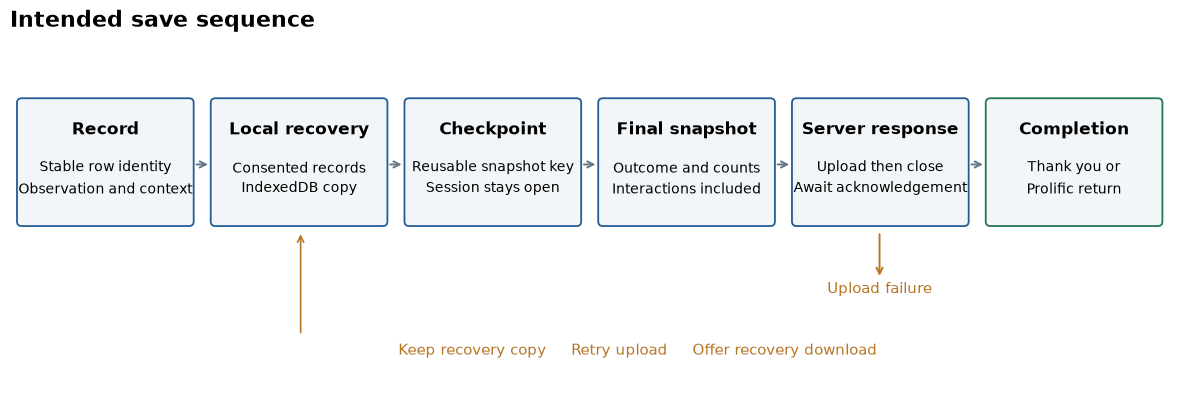

In [2]:
fig, ax = plt.subplots(figsize=(15, 4.7))
ax.set(xlim=(0, 15), ylim=(0, 4.7)); ax.axis('off')
steps = [
    ('Record', 'Stable row identity\nObservation and context'),
    ('Local recovery', 'Consented records\nIndexedDB copy'),
    ('Checkpoint', 'Reusable snapshot key\nSession stays open'),
    ('Final snapshot', 'Outcome and counts\nInteractions included'),
    ('Server response', 'Upload then close\nAwait acknowledgement'),
    ('Completion', 'Thank you or\nProlific return'),
]
for i, (title, body) in enumerate(steps):
    x = .12 + i * 2.5
    ax.add_patch(FancyBboxPatch((x, 2.25), 2.22, 1.6,
        boxstyle='round,pad=.03,rounding_size=.06', facecolor='#f3f6f8', edgecolor=GREEN if i==5 else BLUE, linewidth=1.3))
    ax.text(x+1.11, 3.47, title, ha='center', va='center', fontsize=12, fontweight='bold')
    ax.text(x+1.11, 2.85, body, ha='center', va='center', fontsize=10, linespacing=1.5)
    if i < 5:
        ax.annotate('', xy=(x+2.47, 3.02), xytext=(x+2.25, 3.02), arrowprops={'arrowstyle':'->','color':GREY,'lw':1.4})
ax.annotate('Upload failure', xy=(11.22, 2.15), xytext=(11.22, 1.35), ha='center', color=GOLD,
            arrowprops={'arrowstyle':'<-','color':GOLD,'lw':1.4})
ax.text(8.1, .55, 'Keep recovery copy     Retry upload     Offer recovery download', ha='center', color=GOLD, fontsize=11)
ax.annotate('', xy=(3.75, 2.15), xytext=(3.75, .8), arrowprops={'arrowstyle':'->','color':GOLD,'lw':1.2})
ax.set_title('Intended save sequence', loc='left', fontsize=16, fontweight='bold')
fig.savefig(FIGURES / '01_saving_flow.png', dpi=180, bbox_inches='tight')
plt.show()

## Record structure

| Record | Information retained |
|---|---|
| Every row | Run UUID, row UUID, row sequence, phase, elapsed time, UTC time and schema version |
| Session manifest | Route, optional modules, task versions, assignment and expected counts |
| Design manifest | Immutable item orders, screening material and geometry stored once |
| Task observations | Position, responses, scores, timestamps and presentation diagnostics |
| Instruction events | Screen identity, viewing history and comprehension reviews |
| Response events | Completed memory stages and timeout attempts before the full pair finishes |
| Mouse records | Completed trajectories, raw samples, click events, geometry and device context |
| Interaction events | Focus, visibility, fullscreen and relevant resize changes |
| Session summary | Outcome, exit reason and observed and expected module counts |
| Save receipt | Exact snapshot filename, bytes, rows, hash, disposition and response acknowledgement |

Large immutable designs belong in manifest records. Raw mouse samples belong in their trajectory records. Repeating these payloads on every row wastes space and complicates inspection.

The raw CSV is canonical. Clean analysis tables must preserve original row identifiers and source session identity. A new same day session must create distinct outputs.

## Expected coverage

A completed session with both optional modules normally contains the records below. A screening exit contains the screening records and its terminal summary, without main task, demographic or mouse records. An interrupted session is allowed to contain partial records and must remain distinguishable from a completed session.

The pilot audit continuation option allows a full rehearsal after a failed screening criterion. It preserves the failed criterion and is never a production bypass. Mouse skipping remains a disclosed partial module, not evidence that the entire experiment failed.

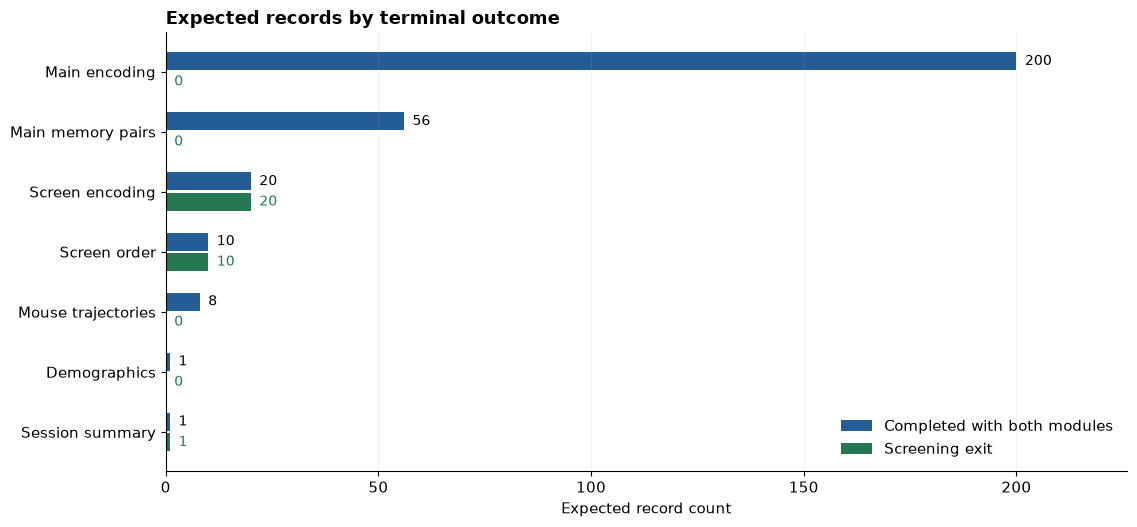

In [3]:
modules = ['Main encoding', 'Main memory pairs', 'Screen encoding', 'Screen order', 'Mouse trajectories', 'Demographics', 'Session summary']
complete_counts = [CONTRACT['main_encoding'], CONTRACT['main_memory_pairs'], CONTRACT['screen_encoding'], CONTRACT['screen_order'], CONTRACT['mouse_trajectories'], 1, 1]
exit_counts = [0, 0, CONTRACT['screen_encoding'], CONTRACT['screen_order'], 0, 0, 1]
fig, ax = plt.subplots(figsize=(11.5, 5.4))
y=np.arange(len(modules))
ax.barh(y-.17, complete_counts, height=.3, color=BLUE, label='Completed with both modules')
ax.barh(y+.17, exit_counts, height=.3, color=GREEN, label='Screening exit')
for i,(a,b) in enumerate(zip(complete_counts, exit_counts)):
    ax.text(a+2, i-.17, str(a), va='center', fontsize=10)
    ax.text(b+2, i+.17, str(b), va='center', fontsize=10, color=GREEN)
ax.set_yticks(y, modules);ax.invert_yaxis();ax.set_xlim(0,max(complete_counts)*1.13)
ax.set_xlabel('Expected record count');ax.set_title('Expected records by terminal outcome', loc='left', fontweight='bold')
ax.legend(frameon=False, loc='lower right');ax.grid(axis='x',alpha=.15)
fig.tight_layout();fig.savefig(FIGURES / '02_expected_records.png', dpi=180, bbox_inches='tight');plt.show()

## Snapshot selection and receipts

The loader ignores byte identical copies and groups checkpoints, recovery copies and final files by run UUID. It prefers the most complete snapshot with a terminal summary and checks overlapping observations for conflicts. Older files without run UUIDs remain separate sessions.

The final receipt must match the exact CSV bytes, SHA256 hash and row count. A receipt reporting an uploaded server response is separated from a local download offer. Absence of a receipt leaves delivery unverified; it does not prove that data were lost. A mismatched receipt is retained as a discrepancy.

A browser unload event is only a fallback. Full CSV files should not be sent as a large unload beacon. A complete final CSV can exceed the browser beacon queue limit. Saving while the page is active and retaining local recovery are the main protections.

Browser behavior is documented in [MDN sendBeacon](https://developer.mozilla.org/en-US/docs/Web/API/Navigator/sendBeacon) and [MDN beforeunload](https://developer.mozilla.org/en-US/docs/Web/API/Window/beforeunload_event). The bundled [Pavlovia transport](../../static/lib/jspsych-pavlovia-3.2.5.js) and [saving controller](../../static/task/data_saving.js) define this task’s implementation.

The final CSV is created before the upload response exists. Its last save event may therefore describe a requested upload. The separate receipt describes the later response. A requested upload in the CSV is not, by itself, evidence that the final upload failed.

## Synthetic audit checks

The following cases are generated into a temporary directory using current task material and deterministic simulated answers. They are labelled synthetic and are never pooled with participant observations. The cases show that the audit accepts a coherent completed record, distinguishes screening exits and interruptions, detects duplicate rows and altered receipts, and respects the explicit pilot continuation route.

In [4]:
with tempfile.TemporaryDirectory(prefix='drone_audit_examples_') as directory:
    generated = audit.make_synthetic_cases(CONTRACT, directory)
    SYNTHETIC = audit.audit_samples(audit.load_samples(directory), CONTRACT)
    case_names = pd.DataFrame({'session':[f'Session {i+1:03d}' for i in range(len(generated))],
                               'Synthetic case':[item['case'] for item in generated]})
    synthetic_summary = case_names.merge(SYNTHETIC['sessions'], on='session', validate='one_to_one')
    display(synthetic_summary[['Synthetic case','outcome','content_status','delivery','n_fail','n_warn']])
    statuses = synthetic_summary.set_index('Synthetic case').content_status
    assert statuses['Complete with receipt'] == 'content_verified'
    assert SYNTHETIC['inventory'].exact_copies_ignored.iloc[0] == 1
    assert synthetic_summary.set_index('Synthetic case').loc['Complete with receipt','snapshots'] == 2
    assert statuses['Screening exit'] == 'content_verified'
    assert statuses['Interrupted session'] == 'interrupted'
    assert statuses['Duplicate record'] == 'issues_found'
    assert statuses['Changed receipt'] == 'issues_found'
    assert statuses['Pilot audit continuation'] == 'content_verified'
    assert synthetic_summary.set_index('Synthetic case').loc['Changed receipt','delivery'] == 'receipt_mismatch'
print('All six synthetic audit expectations were detected.')

,Synthetic case,outcome,content_status,delivery,n_fail,n_warn
0,Complete with receipt,completed,content_verified,server_acknowledged,0,0
1,Screening exit,memory_screened_out,content_verified,server_acknowledged,0,0
2,Interrupted session,interrupted,interrupted,not_observed,0,1
3,Duplicate record,completed,issues_found,server_acknowledged,3,0
4,Changed receipt,completed,issues_found,receipt_mismatch,1,0
5,Pilot audit continuation,completed,content_verified,server_acknowledged,0,0


All six synthetic audit expectations were detected.


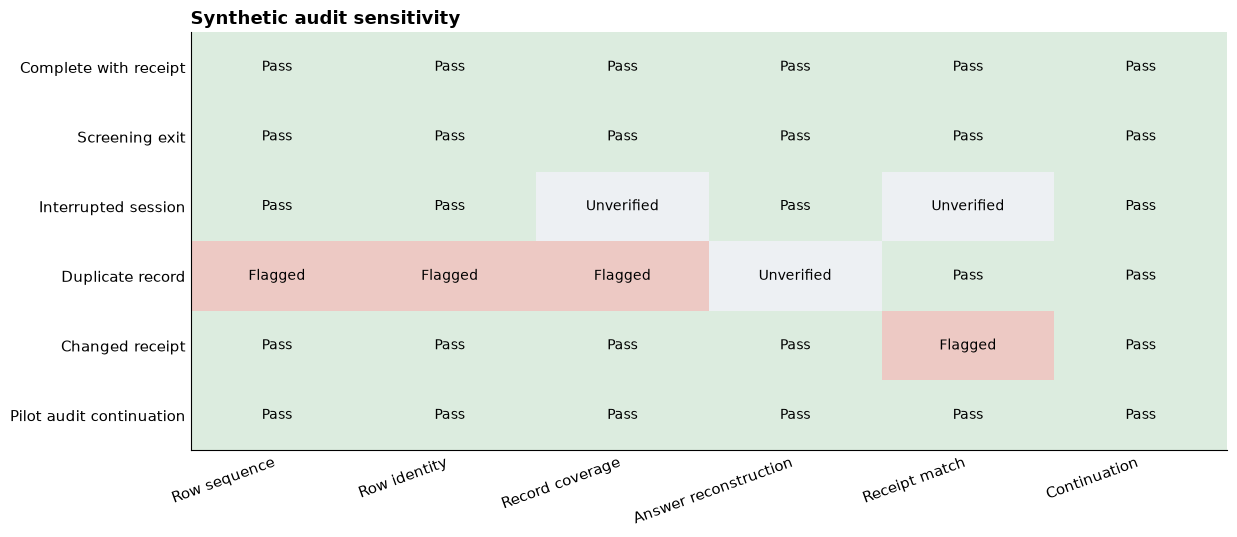

In [5]:
groups = {
 'Row sequence': ['Row sequence complete and ordered'],
 'Row identity': ['Row identifiers unique'],
 'Record coverage': [name for name in SYNTHETIC['checks'].check.unique() if name.startswith('Record count')],
 'Answer reconstruction': ['Screen answer keys reconstruct','Screen criterion agrees'],
 'Receipt match': ['Receipt matches exact snapshot'],
 'Continuation': ['Screen continuation agrees','Production does not bypass screening'],
}
rank={'pass':0,'unverified':1,'warn':2,'fail':3}
matrix=[]
for session in case_names.session:
    selected=SYNTHETIC['checks'].loc[SYNTHETIC['checks'].session.eq(session)]
    matrix.append([max([rank[v] for v in selected.loc[selected.check.isin(names),'status']], default=1) for names in groups.values()])
from matplotlib.colors import ListedColormap
fig,ax=plt.subplots(figsize=(12.5,5.5))
ax.imshow(matrix,cmap=ListedColormap(['#dcecdf','#edf0f3','#f6e4c3','#edc9c4']),vmin=-.5,vmax=3.5,aspect='auto')
labels=['Pass','Unverified','Warning','Flagged']
for y,row in enumerate(matrix):
 for x,v in enumerate(row):ax.text(x,y,labels[v],ha='center',va='center',fontsize=10)
ax.set_yticks(range(len(case_names)),case_names['Synthetic case'])
ax.set_xticks(range(len(groups)),list(groups),rotation=20,ha='right')
ax.set_title('Synthetic audit sensitivity',loc='left',fontweight='bold')
ax.tick_params(length=0);fig.tight_layout();fig.savefig(FIGURES/'03_synthetic_audit.png',dpi=180,bbox_inches='tight');plt.show()

## Audit sample files

Place full raw CSV files and optional receipt JSON files in the private raw directories below. For a full session, use the drone task raw directory. Keep downloaded recovery and checkpoint files with their original final copy so the loader can reconcile the run. Do not place clean table exports here.

| Input | Directory |
|---|---|
| Full experiment | `analysis/data/drone_task/raw` |
| Screening module only | `analysis/data/memory_screen/raw` |
| Mouse module only | `analysis/data/mouse_qc/raw` |

Set `INPUTS` to a specific folder or list of files when reviewing a small new batch. The default reports aggregate counts and ordinal session labels only. Raw identifiers, source filenames and demographic free text remain private and are not printed.

For a full technical rehearsal after the updated task is synced, use the [full audit route](https://run.pavlovia.org/jiaheyi/DroneTask/?pilot=1&mouse_qc=1&memory_screen=1&audit_full=1). It keeps the screening result but allows the full pilot to continue even below the criterion. For a normal screening exit rehearsal, use [the normal criterion route](https://run.pavlovia.org/jiaheyi/DroneTask/?pilot=1&mouse_qc=1&memory_screen=1&audit_full=0).

At the end, select **Download CSV** and **Download save receipt** separately. Retain both the CSV and the receipt JSON when supplied. Place them together in the full experiment raw directory. Technical rehearsals using the audit continuation route should remain separate from the research sample.

In [6]:
INPUTS = audit.DEFAULT_INPUTS
WRITE_EXPORTS = True
OBSERVED_INPUT = audit.load_samples(INPUTS)
OBSERVED = audit.audit_samples(OBSERVED_INPUT, CONTRACT)
display(OBSERVED['inventory'])
if len(OBSERVED['input_errors']):
    display(OBSERVED['input_errors'])
if len(OBSERVED['sessions']):
    display(OBSERVED['sessions'])
    current = OBSERVED['sessions'].schema.eq('current')
    if not current.any():
        print('Only legacy sessions are available. The current saving protocol has no observed full session validation yet.')
    display(OBSERVED['coverage'])
    discrepancies = OBSERVED['checks'].loc[OBSERVED['checks'].status.ne('pass')]
    display(discrepancies)
else:
    print('No raw participant snapshots are available. No observed completion or delivery rate is estimated.')
if WRITE_EXPORTS:
    display(pd.DataFrame({'Private audit export':audit.export_report(OBSERVED, OUTPUT)}))

,unique_csv,exact_copies_ignored,receipts,read_errors,sessions
0,2,0,0,0,2


,session,schema,outcome,content_status,rows,bytes,snapshots,selected_kind,delivery,n_fail,n_warn
0,Session 001,legacy,legacy,legacy,312,2148148,1,raw,not_observed,0,0
1,Session 002,legacy,legacy,legacy,308,2116555,1,raw,not_observed,0,0


Only legacy sessions are available. The current saving protocol has no observed full session validation yet.


,session,module,expected,observed,status
0,Session 001,main_encoding,None,200,unverified
1,Session 001,main_memory_pairs,None,56,unverified
2,Session 001,screen_encoding,None,0,unverified
3,Session 001,screen_order,None,0,unverified
4,Session 001,demographics,None,1,unverified
5,Session 001,mouse_trajectories,None,0,unverified
6,Session 001,mouse_summary,None,0,unverified
7,Session 002,main_encoding,None,200,unverified
8,Session 002,main_memory_pairs,None,56,unverified
9,Session 002,screen_encoding,None,0,unverified


,session,check,status,detail
0,Session 001,Current schema available,unverified,legacy
5,Session 002,Current schema available,unverified,legacy


,Private audit export
0,inventory.csv
1,sessions.csv
2,checks.csv
3,coverage.csv
4,snapshots.csv
5,input_errors.csv


## Reading the results

| Result | Meaning |
|---|---|
| Content verified | The available snapshot passes the implemented record checks |
| Issues found | At least one content or receipt integrity check failed |
| Interrupted | Current schema without a terminal summary; retain partial data |
| Legacy | Older schema; current protocol cannot be verified retrospectively |
| Server acknowledged | A matching supplied receipt reports an uploaded server response |
| Local copy offered | A matching receipt describes a prepared local download |
| Not observed | No usable delivery receipt was supplied |

Content verified does not establish scientific validity, participant attention or absence of every possible implementation bug. Mouse truncation and intentional skipping are reported separately. Poor memory performance is not a technical saving failure.

Audit the saved file from a full new rehearsal, then a genuine screening exit, an intentional early exit and a network failure rehearsal. Compare the saved snapshot and receipt after reconnecting. Browser testing should verify that the participant is not told that saving succeeded before the response arrives.

A separate Chrome rehearsal of the actual survey route was audited using synthetic age and multiple race selections. It produced one demographics record and a matching local receipt, correctly classified as a local copy rather than a confirmed cloud save. This component rehearsal does not establish full experiment delivery across all modules.

An additional integration fixture passed through the actual Recorder with synthetic observations and a mocked transport response. Its reconstructed counts were 200 main encoding records, 56 main memory pairs, 20 screening turns, 10 screening questions, 8 mouse trajectories and one demographics record. The resulting CSV and matching receipt passed the audit. This verifies local integration and serialization, not a live Pavlovia upload.

## Command line use

The same audit can run without opening this notebook.

```sh
python design_checks/scripts/data_saving_audit.py
python design_checks/scripts/data_saving_audit.py /path/to/sample/folder --output analysis/data/drone_task/derived/data_saving_audit
```

The command reads files and writes private audit tables. It does not upload data, approve Prolific submissions or modify raw files.

## Source provenance

Expected counts and material come from the JavaScript modules evaluated in setup. File hashes below identify the implementation inspected by this run. They do not replace the build identifier recorded in each sample.

In [7]:
with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame([{'Source':path,'SHA256':digest}
                          for path,digest in CONTRACT['source_hashes'].items()]))

,Source,SHA256
0,static/task/data_saving.js,c2531bda5009684a2b16ccff357232184f021ba20a64536dbc545acc8fac7aaf
1,static/task/data_recorder.js,445fd62032238d051fd65a6591d19db2ffbe4c55865e13e1c8b84d91082b50e4
2,static/lib/jspsych-pavlovia-3.2.5.js,2ba56c9f06956428e82750493b34bf5e48fbf4edc3b7868c86fbdb7876d99db7
3,index.html,1a17dfe65e71bb7a8a0d57469bd6f5d0ffa1db8be75a6c0c7c1815bcad9a0c9c
4,static/task/memory_screening/memory_screening.js,696fd4396e591442eb32d7af6b3e216ad6d04dad0eba63628cd439d7e3d98b4e
5,static/task/mouse_qc/mouse_trajectory.js,8897ca23608e9448e4c5eefcc1f68a3eeab104267f974f2829e847911ffa24a1
6,analysis/split_drone_data.py,0bc930beb9d7e0943d98474c8f873a7e5f5a69cfa37ad64a34f61f7d9293f2af
